# CP2 - Data Readiness: Toba Health Insight

**SIMULASI. BUKAN HASIL PENELITIAN AKTUAL.** Dua CSV merupakan fixture sintetis. Notebook ini menjalankan ETL/EDA di memori, tidak menghubungi database, tidak melatih model, dan tidak menimpa raw data. Pilih kernel `.venv` project lalu Run All. Kontrak kolom dan aturan ada di `docs/DATA_DICTIONARY.md`.

In [1]:
from pathlib import Path
import sys, os, hashlib
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/sample').is_dir())
sys.path.insert(0, str(ROOT))
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / 'reports/.matplotlib'))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from backend.app.pipeline import prepare
from backend.app.readiness import analyze, make_figures
get_ipython().run_line_magic('matplotlib', 'inline')
plt.ioff()
paths = [ROOT / 'data/sample' / name for name in ['Data_Responden_Sintetis.csv', 'Data_Harian_Sintetis.csv']]
hashes_before = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
raw_profiles, raw_daily = [pd.read_csv(p, dtype=str, keep_default_na=False) for p in paths]
print('SIMULASI: shapes', raw_profiles.shape, raw_daily.shape)
# Nama tidak pernah ditampilkan dalam output notebook.
display(raw_profiles.drop(columns=[raw_profiles.columns[2]]).head(3))
display(raw_daily.head(3))

SIMULASI: shapes (19, 24) (570, 28)


,Timestamp,1. ID Responden,3. Berapa usia anda saat ini (Contoh: 22 tahun),4. Apa jenis kelamin anda?,5. Di provinsi mana Anda tinggal saat ini? (Contoh: Sumatera Utara),6. Di kabupaten atau kota mana Anda tinggal saat ini? (Contoh: Toba Samosir),7. Apa pekerjaan atau kegiatan utama Anda saat ini?,9. Apa pendidikan terakhir yang telah Anda selesaikan?,10. Apakah Anda pernah didiagnosis memiliki tekanan darah tinggi oleh tenaga kesehatan?,11. Apakah saat ini Anda menggunakan obat yang diresepkan untuk tekanan darah tinggi?,...,15. Apakah Anda pernah didiagnosis penyakit jantung oleh tenaga kesehatan?,16. Apakah Anda pernah didiagnosis mengalami stroke oleh tenaga kesehatan?,17. Apakah ibu kandung Anda pernah didiagnosis memiliki tekanan darah tinggi?,18. Apakah ayah kandung Anda pernah didiagnosis memiliki tekanan darah tinggi?,20. Apakah orang tua kandung atau saudara kandung Anda pernah didiagnosis diabetes?,21. Apakah orang tua kandung atau saudara kandung Anda pernah didiagnosis penyakit jantung atau mengalami stroke?,"22. Berapa tinggi badan Anda? (Masukkan dalam sentimeter (cm), misalnya 165 cm)",23. Berapa berat badan Anda? (Masukkan dalam kilogram misalnya 45 kg),24. Aktivitas fisik atau olahraga apa yang biasanya Anda lakukan? (boleh memilih lebih dari satu),"25. Dalam satu minggu biasa, berapa hari Anda melakukan aktivitas fisik yang membuat napas atau denyut jantung sedikit lebih cepat?"
0,2026-08-28 09:37:00,SIM001,55,Laki-laki,Sumatera Utara,Toba,Tidak bekerja saat ini,SMA atau SMK atau sederajat,Tidak,Tidak,...,Tidak,Tidak,Tidak,Tidak,Ya,Tidak,161,60.7,"Olahraga permainan, seperti bulu tangkis, sepa...",7 hari
1,2026-08-28 10:14:00,SIM002,22,Laki-laki,Sumatera Utara,Samosir,Pelajar atau mahasiswa,Sarjana,Ya,Ya,...,Tidak,Tidak,Tidak,Tidak,Tidak,Tidak,177,77.3,"Pekerjaan fisik, seperti bertani, mengangkat b...",3 hari
2,2026-08-28 10:51:00,SIM003,59,Laki-laki,Sumatera Utara,Medan,Pekerja lapangan atau pekerjaan fisik,Diploma,Ya,Ya,...,Tidak,Tidak,Tidak,Ya,Tidak,Tidak,175,99.5,"Jalan kaki untuk pergi bekerja, sekolah, berbe...",7 hari


,Timestamp,1. ID Responden,2. Tanggal pengamatan,3. Pukul berapa Anda mengukur tekanan darah pagi ini?,4. Berapa angka atas (sistolik) pada pembacaan pertama?,6. Berapa angka bawah (diastolik) pada pembacaan pertama?,7. Berapa angka atas (sistolik) pada pembacaan kedua?,8. Berapa angka bawah (diastolik) pada pembacaan kedua?,"9. Dalam 30 menit sebelum pengukuran pagi, apakah Anda melakukan salah satu kegiatan berikut?",10. Pukul berapa Anda mengukur tekanan darah malam ini?,...,"19. Kira-kira berapa lama total Anda duduk atau hanya sedikit bergerak hari ini, di luar waktu tidur?",20. Berapa jam Anda tidur tadi malam?,"21. Hari ini, berapa kali Anda makan makanan asin atau makanan olahan?","22. Hari ini, berapa porsi buah yang Anda makan?","23. Hari ini, berapa porsi sayur yang Anda makan?","24. Hari ini, berapa gelas atau cangkir minuman berkafein yang Anda konsumsi?\nContoh: kopi, teh, atau minuman energi.",25. Apakah anda merokok hari ini?,Berapa kali anda merokok hari ini?,"26. Jika Anda menggunakan obat yang diresepkan untuk tekanan darah, apakah Anda minum obat sesuai petunjuk hari ini?",27. Seberapa besar stres yang Anda rasakan hari ini?
0,2026-09-01 21:34:00,SIM001,2026-09-01,07:22,123,70,120,67,Berolahraga,19:57,...,Lebih dari 10 jam,06:05,1 kali,1 porsi,Tidak mengonsumsi sayur,3 gelas atau lebih,Tidak berlaku karena saya tidak merokok,,Saya tidak menggunakan obat tekanan darah,1 = Sangat rendah
1,2026-09-02 21:02:00,SIM001,2026-09-02,06:07,117,71,115,70,Tidak ada kegiatan di atas,19:31,...,4–7 jam,04:48,2 kali,3 porsi atau lebih,1 porsi,1 gelas,Tidak berlaku karena saya tidak merokok,,Saya tidak menggunakan obat tekanan darah,5 = Sangat tinggi
2,2026-09-03 21:10:00,SIM001,2026-09-03,06:21,122,74,120,74,Tidak ada kegiatan di atas,20:41,...,Kurang dari 4 jam,06:35,1 kali,2 porsi,2 porsi,1 gelas,Tidak berlaku karena saya tidak merokok,,Saya tidak menggunakan obat tekanan darah,2 = Rendah


## 1. Audit sumber, cleaning, dan grain

Sumber dipertahankan. Parser menerima satuan sesuai kolom, menahan duplikasi/ID tanpa profil, dan mencatat sel invalid. Missing tetap NA. Tidur HH:MM hanya diasumsikan durasi pada fixture sintetis; aktual menunggu konfirmasi. Outlier statistik tidak dihapus otomatis.

In [2]:
profiles, days, sessions, quality = prepare(raw_profiles, raw_daily, synthetic=True)
display(pd.DataFrame(quality['row_outcomes']).T)
print('SIMULASI: uniqueness', quality['uniqueness'])
print('Consistency issues:', quality['consistency']['issues'])
print('Quarantine:', quality['profile_rejections'], quality['rejections'])
assert len({p['respondent_id'] for p in profiles}) == len(profiles)
assert len({(d['respondent_id'], d['date']) for d in days}) == len(days)
assert len({(s['respondent_id'], s['date'], s['session']) for s in sessions}) == len(sessions)
assert all(d['respondent_id'] in {p['respondent_id'] for p in profiles} for d in days)
before, after = pd.DataFrame(quality['before']), pd.DataFrame(quality['after'])
display(before[['source','field','rows','missing','missing_percent','invalid','noncanonical']])
display(after[['source','field','rows','missing','missing_percent','invalid']])
print('Issues:', quality['issue_counts'])
print('Sumber tidak berubah:', hashes_before == {p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in paths})

,raw,accepted,quarantined,rejected_schema,derived,valid,incomplete
profiles,19.0,19.0,0.0,0.0,NaN,NaN,NaN
daily,570.0,570.0,0.0,0.0,NaN,NaN,NaN
sessions,NaN,NaN,NaN,NaN,1140.0,1140.0,0.0


SIMULASI: uniqueness {'profile_duplicate_excess': 0, 'daily_duplicate_excess': 0, 'clean_profile_duplicate_excess': 0, 'clean_daily_duplicate_excess': 0}
Consistency issues: []
Quarantine: [] []


,source,field,rows,missing,missing_percent,invalid,noncanonical
0,profiles,submitted_at,19,0,0.000,0,0
1,profiles,respondent_id,19,0,0.000,0,0
2,profiles,direct_identity,19,0,0.000,0,0
3,profiles,age,19,0,0.000,0,0
4,profiles,gender,19,0,0.000,0,0
5,profiles,province,19,0,0.000,0,0
6,profiles,city,19,0,0.000,0,0
7,profiles,occupation,19,0,0.000,0,0
8,profiles,education,19,0,0.000,0,0
9,profiles,diagnosed_bp,19,0,0.000,0,0


,source,field,rows,missing,missing_percent,invalid
0,profiles,submitted_at,19,0.0,0.000,0.0
1,profiles,respondent_id,19,0.0,0.000,0.0
2,profiles,direct_identity,19,NaN,NaN,NaN
3,profiles,age,19,0.0,0.000,0.0
4,profiles,gender,19,0.0,0.000,0.0
5,profiles,province,19,0.0,0.000,0.0
6,profiles,city,19,0.0,0.000,0.0
7,profiles,occupation,19,0.0,0.000,0.0
8,profiles,education,19,0.0,0.000,0.0
9,profiles,diagnosed_bp,19,0.0,0.000,0.0


Issues: {}
Sumber tidak berubah: True


## 2. Statistik deskriptif

Profil dihitung per orang; tekanan darah per sesi; perilaku dan korelasi per ID-tanggal. Angka pada responden berulang tidak diperlakukan sebagai observasi independen.

In [3]:
eda = analyze(profiles, days, sessions, quality)
p, d, s = eda['profiles'], eda['daily'], eda['valid_sessions']
display(p[['age','height_cm','weight_kg','bmi','active_days_week']].describe())
display(s[['sbp1','dbp1','sbp2','dbp2','sbp_mean','dbp_mean']].describe())
display(d[['sleep_hours','activity_minutes','heavy_minutes','stress','sbp_mean','dbp_mean']].describe())
figures = make_figures(eda, quality)
for fig in figures.values(): plt.close(fig)

,age,height_cm,weight_kg,bmi,active_days_week
count,19.000000,19.000000,19.000000,19.000000,19.000000
mean,41.421053,162.631579,66.257895,24.990053,5.578947
std,13.001349,8.914473,13.362149,4.275109,1.464991
min,20.000000,150.000000,50.000000,19.408000,3.000000
25%,32.500000,156.500000,54.050000,22.252000,4.500000
50%,41.000000,163.000000,64.500000,24.110000,6.000000
75%,53.500000,167.500000,76.600000,27.450000,7.000000
max,59.000000,180.000000,99.500000,32.678000,7.000000


,sbp1,dbp1,sbp2,dbp2,sbp_mean,dbp_mean
count,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000,1140.000000
mean,119.907895,73.341228,117.923684,71.818421,118.915789,72.579825
std,7.296152,3.931622,7.374133,4.069352,7.307309,3.971832
min,101.000000,62.000000,99.000000,60.000000,100.500000,61.500000
25%,115.000000,71.000000,113.000000,69.000000,113.500000,70.000000
50%,119.000000,73.000000,117.000000,72.000000,118.500000,72.500000
75%,124.000000,76.000000,122.000000,74.000000,123.000000,75.000000
max,146.000000,88.000000,143.000000,86.000000,144.500000,87.000000


,sleep_hours,activity_minutes,heavy_minutes,stress,sbp_mean,dbp_mean
count,564.000000,570.000000,570.000000,570.000000,570.000000,570.000000
mean,7.010374,44.649123,8.500000,3.003509,118.915789,72.579825
std,0.914256,37.464214,12.488483,1.132670,6.970905,3.563168
min,4.800000,0.000000,0.000000,1.000000,102.750000,62.500000
25%,6.383000,15.000000,0.000000,2.000000,114.000000,70.000000
50%,6.983000,40.000000,0.000000,3.000000,118.500000,72.500000
75%,7.658250,75.000000,15.000000,4.000000,122.750000,74.500000
max,9.483000,120.000000,40.000000,5.000000,142.000000,84.500000


## 3. Demografi: usia, jenis kelamin, dan lokasi

Semua grafik berlabel SIMULASI; unit hitung profil adalah orang. Lokasi mengikuti provinsi dan kabupaten/kota, bukan kecamatan.

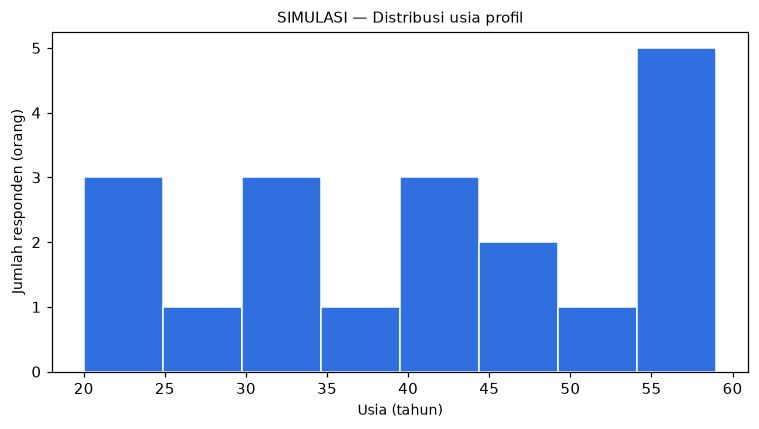

SIMULASI: usia 20-59 tahun; rerata 41.42 tahun, n=19 profil.

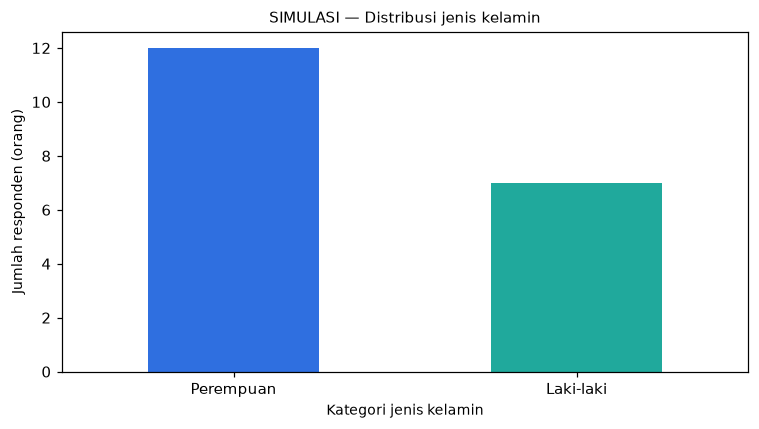

,jumlah_profil
gender,
Perempuan,12
Laki-laki,7


Interpretasi: batang menghitung profil unik per kategori, bukan sesi pengukuran.

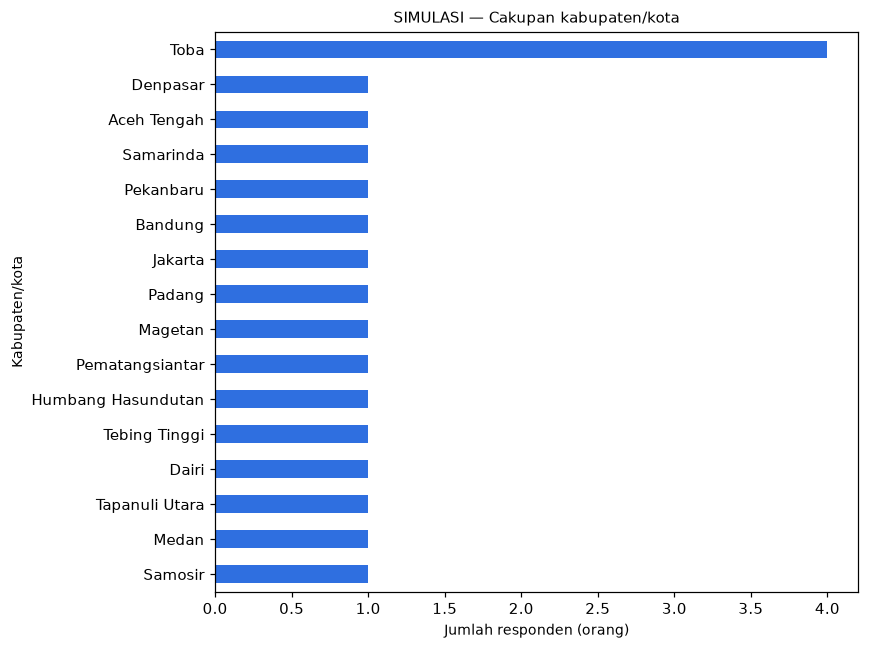

,,jumlah_profil
province,city,
Aceh,Aceh Tengah,1
Bali,Denpasar,1
DKI Jakarta,Jakarta,1
Jawa Barat,Bandung,1
Jawa Timur,Magetan,1
Kalimantan Timur,Samarinda,1
Riau,Pekanbaru,1
Sumatera Barat,Padang,1
Sumatera Utara,Dairi,1


SIMULASI: 9 provinsi dan 16 kabupaten/kota; cakupan ini tidak mewakili populasi wilayah.

In [4]:
display(figures['01_profile_age.png'])
display(Markdown(f"SIMULASI: usia {p.age.min():.0f}-{p.age.max():.0f} tahun; rerata {p.age.mean():.2f} tahun, n={len(p)} profil."))
display(figures['02_profile_gender.png'])
display(p.gender.value_counts().rename('jumlah_profil').to_frame())
display(Markdown('Interpretasi: batang menghitung profil unik per kategori, bukan sesi pengukuran.'))
display(figures['03_profile_location.png'])
display(p.groupby(['province','city']).size().rename('jumlah_profil').to_frame())
display(Markdown(f"SIMULASI: {p.province.nunique()} provinsi dan {p.city.nunique()} kabupaten/kota; cakupan ini tidak mewakili populasi wilayah."))

## 4. Distribusi sistolik/diastolik dan perbandingan pagi-malam

Rata-rata sesi dihitung dari pembacaan valid; SBP1/DBP1/SBP2/DBP2 tetap tersimpan. Kotak menunjukkan median/IQR, bukan batas diagnosis.

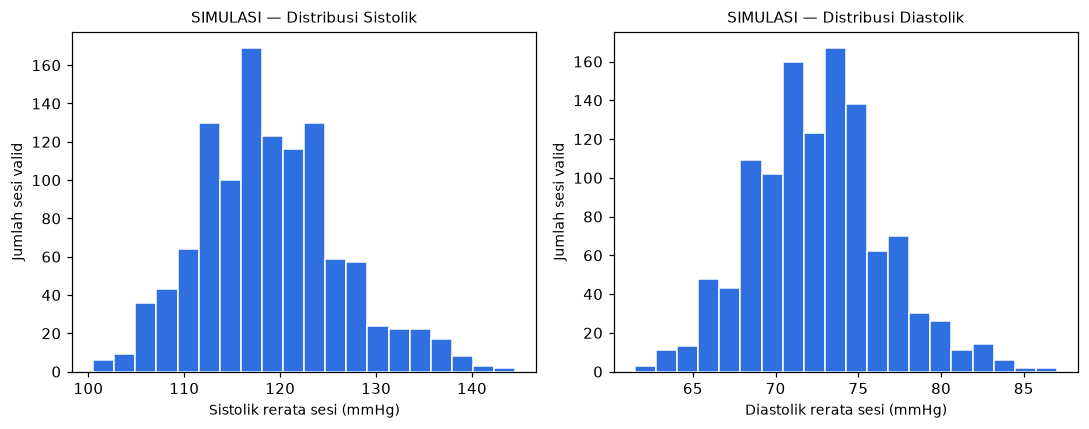

SIMULASI: rerata SBP 118.916 mmHg dan DBP 72.580 mmHg pada 1140 sesi valid.

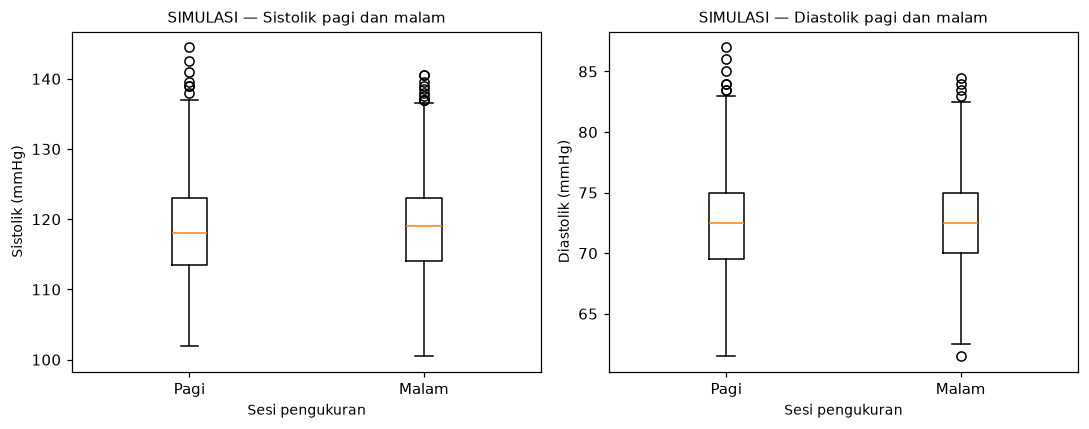

sbp_mean                       dbp_mean                     
           count        mean       std    count       mean       std
session                                                             
Malam        570  119.150877  7.344166      570  72.723684  3.827045
Pagi         570  118.680702  7.269104      570  72.435965  4.109852

SIMULASI: 570 pasangan ID-tanggal lengkap; rerata selisih Malam−Pagi 0.470 mmHg. Perbandingan memasangkan orang dan tanggal yang sama; ini statistik deskriptif, bukan efek kausal waktu.

In [5]:
display(figures['04_pressure_distribution.png'])
display(Markdown(f"SIMULASI: rerata SBP {s.sbp_mean.mean():.3f} mmHg dan DBP {s.dbp_mean.mean():.3f} mmHg pada {len(s)} sesi valid."))
display(figures['05_session_comparison.png'])
display(s.groupby('session')[['sbp_mean','dbp_mean']].agg(['count','mean','std']))
display(Markdown(eda['summary']['findings'][1]['text']))

## 5. Tren menurut tanggal

Garis merupakan rerata sesi valid tiap tanggal. Perubahan rerata dapat dipengaruhi komposisi data yang tersedia.

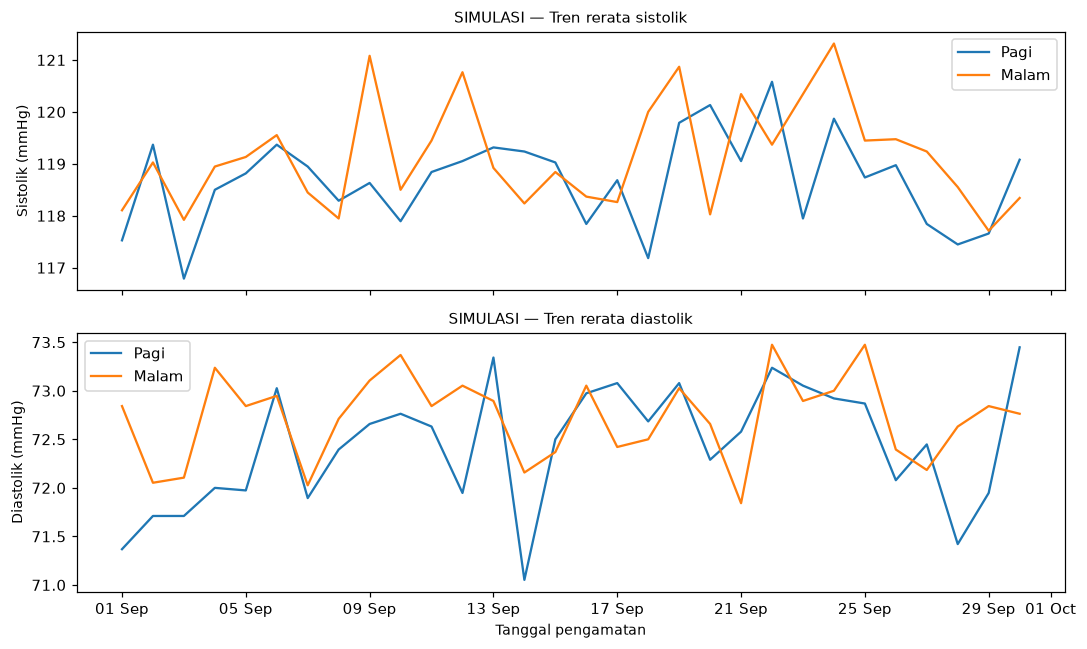

,date,session,sbp_mean,dbp_mean
0,2026-09-01,Malam,118.105263,72.842105
1,2026-09-01,Pagi,117.526316,71.368421
2,2026-09-02,Malam,119.026316,72.052632
3,2026-09-02,Pagi,119.368421,71.710526
4,2026-09-03,Malam,117.921053,72.105263


SIMULASI: rerata sistolik sesi pada 2026-09-01 adalah 117.816 mmHg dan pada 2026-09-30 118.711 mmHg (selisih +0.895 mmHg). Dua titik ini bukan bukti tren populasi atau perubahan klinis.

In [6]:
display(figures['06_daily_trend.png'])
display(eda['trend'].head())
display(Markdown(eda['summary']['findings'][2]['text']))

## 6. Tidur, aktivitas fisik, dan stres

Satu titik = satu ID-tanggal. Tidur memakai asumsi simulasi; aktivitas dalam menit/hari; stres skala 1-5. Grafik merupakan asosiasi deskriptif.

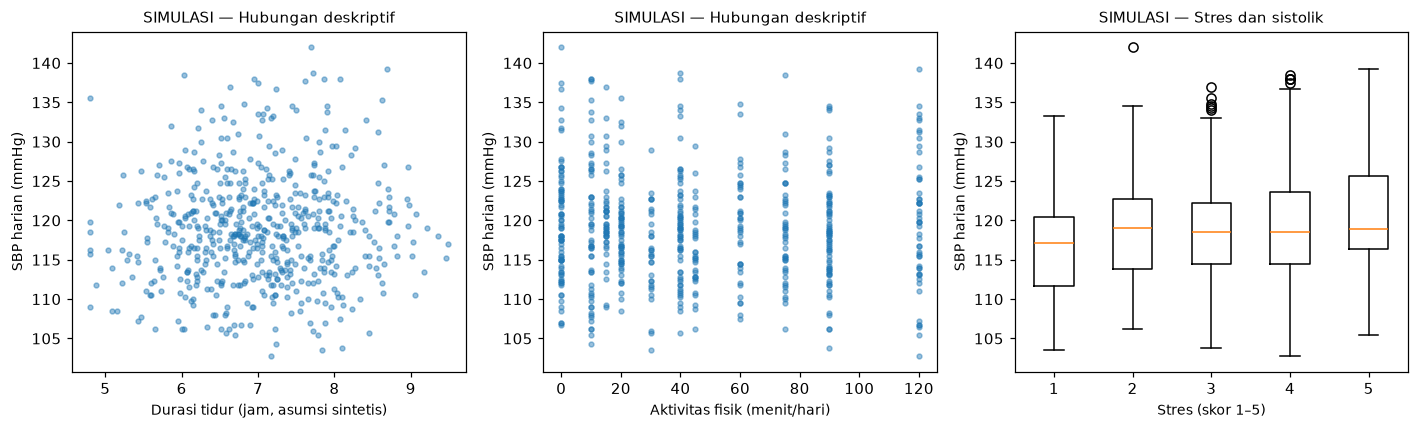

,count,mean,std
stress,,,
1,64,117.195312,7.152737
2,114,118.649123,6.683648
3,206,118.646845,6.243531
4,128,119.681641,7.520164
5,58,120.603448,8.113779


SIMULASI: 564 catatan memiliki durasi tidur, 570 aktivitas menit, dan 570 stres. Kotak per skor stres merangkum distribusi SBP, bukan efek kausal stres.

In [7]:
display(figures['07_lifestyle.png'])
display(d.groupby('stress').sbp_mean.agg(['count','mean','std']))
display(Markdown(f"SIMULASI: {d.sleep_hours.notna().sum()} catatan memiliki durasi tidur, {d.activity_minutes.notna().sum()} aktivitas menit, dan {d.stress.notna().sum()} stres. Kotak per skor stres merangkum distribusi SBP, bukan efek kausal stres."))

## 7. Korelasi numerik

Pearson dihitung pairwise pada data harian. Missing dikeluarkan hanya per pasangan; tidak diimputasi. Korelasi NA tidak diubah menjadi nol. Tidak ada klaim signifikansi atau sebab-akibat.

,age,bmi,sleep_hours,activity_minutes,heavy_minutes,stress,sbp_mean,dbp_mean
age,1.000000,-0.256559,0.019895,0.072572,-0.038833,0.053677,0.537065,0.502428
bmi,-0.256559,1.000000,0.054506,-0.007852,-0.013243,0.041530,0.321427,0.275530
sleep_hours,0.019895,0.054506,1.000000,-0.027708,-0.020013,0.022696,0.058821,0.076277
activity_minutes,0.072572,-0.007852,-0.027708,1.000000,0.143303,0.015353,-0.012327,0.030079
heavy_minutes,-0.038833,-0.013243,-0.020013,0.143303,1.000000,0.019009,-0.039709,-0.048105
stress,0.053677,0.041530,0.022696,0.015353,0.019009,1.000000,0.121179,0.092683
sbp_mean,0.537065,0.321427,0.058821,-0.012327,-0.039709,0.121179,1.000000,0.814436
dbp_mean,0.502428,0.275530,0.076277,0.030079,-0.048105,0.092683,0.814436,1.000000


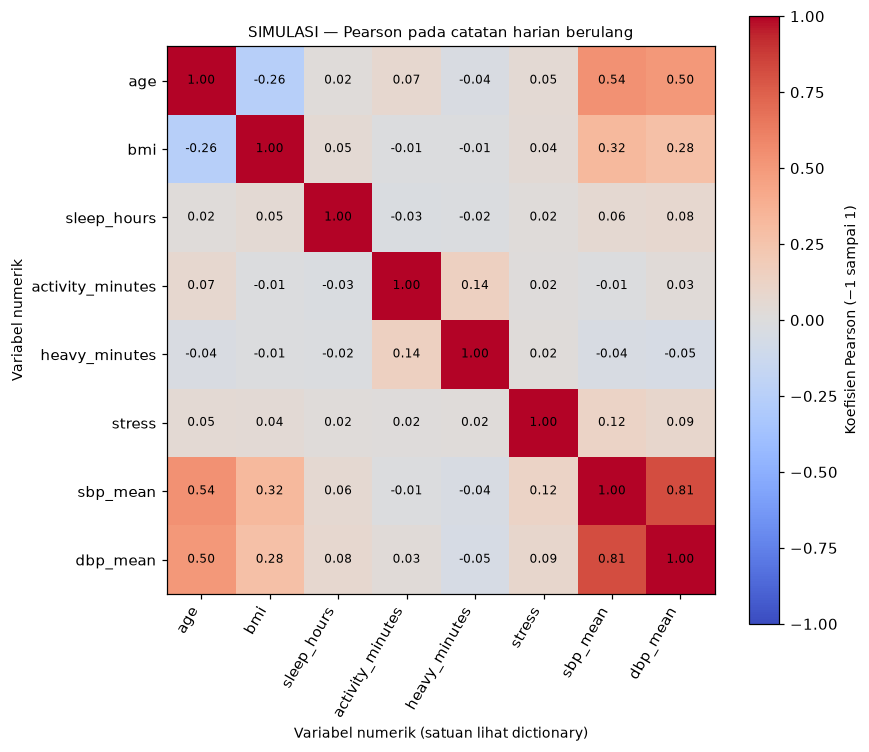

SIMULASI: korelasi Pearson aktivitas menit–SBP harian -0.012; tidur–SBP harian 0.059. Perhitungan satu baris per ID-tanggal, bukan menduplikasi perilaku ke dua sesi. Catatan dari orang yang sama saling berkaitan; tidak digunakan untuk uji kausal atau signifikansi populasi.

In [8]:
display(eda['correlation'])
display(figures['08_numeric_correlation.png'])
display(Markdown(eda['summary']['findings'][3]['text']))

## 8. Missing, duplikasi, dan outlier

Tekanan darah di luar pagar teknis menjadi NA dengan alasan. Nilai yang lolos pagar tetapi ditandai IQR atau SBP<=DBP dipertahankan untuk review. Periksa juga masalah relasi dan pasangan ID-tanggal, bukan hanya distribusi.

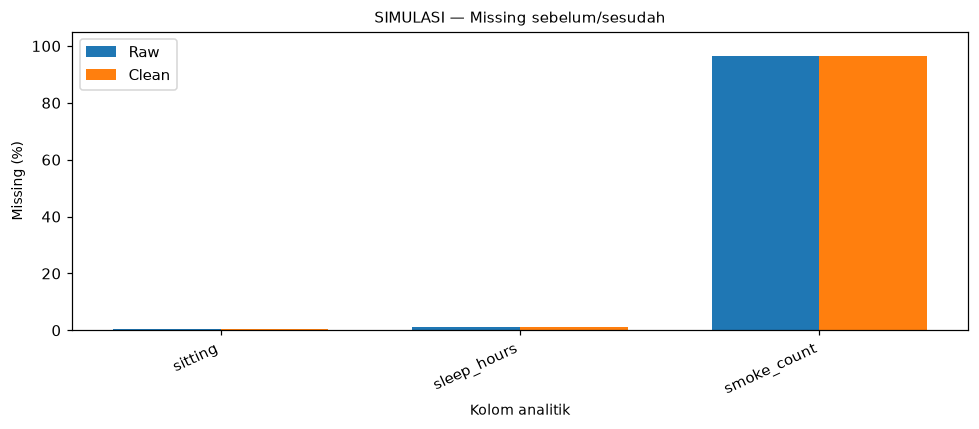

SIMULASI: tidur kosong 6/570 (1.053%), duduk kosong 3/570 (0.526%). Jumlah merokok NA 550/570; status merokok tidak dipakai untuk mengisi nol. 25 sesi diberi flag IQR; tidak ada sesi yang dihapus hanya karena flag statistik.

,session,field,n,q1,q3,lower,upper,flagged
0,Pagi,sbp_mean,570,113.5,123.0,99.25,137.25,7
1,Pagi,dbp_mean,570,69.5,75.0,61.25,83.25,7
2,Malam,sbp_mean,570,114.0,123.0,100.50,136.50,11
3,Malam,dbp_mean,570,70.0,75.0,62.50,82.50,5


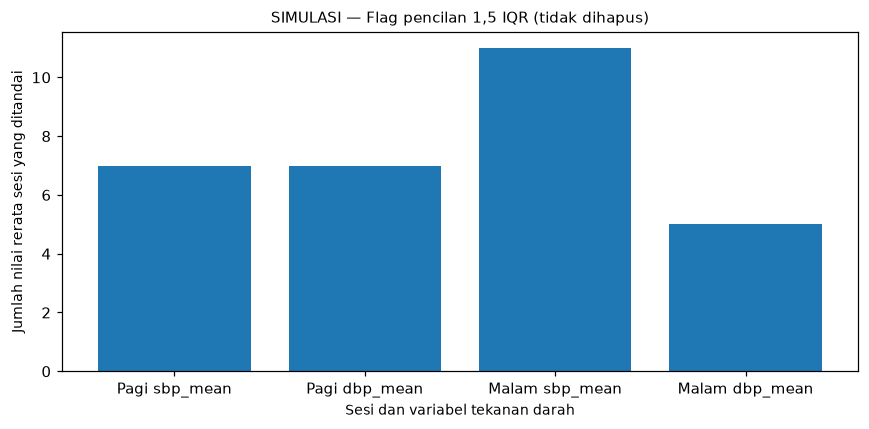

SIMULASI: 25 sesi memiliki flag IQR; 0 sel pembacaan invalid; 0 pasangan duplikat. Jumlah sesi yang dihapus karena flag IQR = 0.

,session_index,source_row,session,field,value,action,method
0,121,62,Pagi,sbp_mean,139.5,retain_for_review,1.5 IQR within session
1,123,63,Pagi,sbp_mean,144.5,retain_for_review,1.5 IQR within session
2,127,65,Pagi,sbp_mean,138.0,retain_for_review,1.5 IQR within session
3,149,76,Pagi,sbp_mean,142.5,retain_for_review,1.5 IQR within session
4,151,77,Pagi,sbp_mean,139.0,retain_for_review,1.5 IQR within session
5,153,78,Pagi,sbp_mean,139.0,retain_for_review,1.5 IQR within session
6,163,83,Pagi,sbp_mean,141.0,retain_for_review,1.5 IQR within session
7,127,65,Pagi,dbp_mean,83.5,retain_for_review,1.5 IQR within session
8,129,66,Pagi,dbp_mean,86.0,retain_for_review,1.5 IQR within session
9,135,69,Pagi,dbp_mean,87.0,retain_for_review,1.5 IQR within session


In [9]:
display(figures['09_missing_before_after.png'])
display(Markdown(eda['summary']['findings'][4]['text']))
display(pd.DataFrame(quality['pressure_anomalies']['summaries']))
display(figures['10_pressure_anomalies.png'])
display(Markdown(f"SIMULASI: {quality['pressure_anomalies']['flagged_sessions']} sesi memiliki flag IQR; {quality['invalid_bp_count']} sel pembacaan invalid; {quality['duplicate_pairs']} pasangan duplikat. Jumlah sesi yang dihapus karena flag IQR = {quality['pressure_anomalies']['removed_sessions']}."))
display(pd.DataFrame(quality['pressure_anomalies']['flags']).head(20))

## 9. Lima temuan dan batas kesiapan CP2

Temuan berikut sama dengan generator laporan. Periksa kualitas data aktual, persetujuan sumber, definisi tidur, dan kriteria inklusi sebelum menarik kesimpulan penelitian.

In [10]:
for number, finding in enumerate(eda['summary']['findings'], 1):
    display(Markdown('### ' + str(number) + '. ' + finding['title'] + chr(10) + finding['text']))
assert hashes_before == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in paths}
assert len(profiles) == quality['accepted_profiles']
assert len(days) == quality['accepted_daily']
assert len(sessions) == quality['row_outcomes']['sessions']['derived']
for fig in figures.values(): plt.close(fig)
print('CP2 teknis SIMULASI: audit, transformasi, statistik, dan grafik selesai. Tidak ada perubahan raw atau database.')

### 1. Cakupan profil dan variasi demografi
SIMULASI: 19 ID, 30 tanggal, 570 catatan harian dan 1140 sesi valid. Usia 20–59 tahun, rerata 41.42; 9 provinsi dan 16 kabupaten/kota. Jumlah catatan berulang tidak sama dengan jumlah orang.

### 2. Perbandingan pagi–malam berpasangan
SIMULASI: 570 pasangan ID-tanggal lengkap; rerata selisih Malam−Pagi 0.470 mmHg. Perbandingan memasangkan orang dan tanggal yang sama; ini statistik deskriptif, bukan efek kausal waktu.

### 3. Perubahan rerata harian selama periode simulasi
SIMULASI: rerata sistolik sesi pada 2026-09-01 adalah 117.816 mmHg dan pada 2026-09-30 118.711 mmHg (selisih +0.895 mmHg). Dua titik ini bukan bukti tren populasi atau perubahan klinis.

### 4. Hubungan gaya hidup pada grain harian
SIMULASI: korelasi Pearson aktivitas menit–SBP harian -0.012; tidur–SBP harian 0.059. Perhitungan satu baris per ID-tanggal, bukan menduplikasi perilaku ke dua sesi. Catatan dari orang yang sama saling berkaitan; tidak digunakan untuk uji kausal atau signifikansi populasi.

### 5. Missing tetap terlihat setelah cleaning
SIMULASI: tidur kosong 6/570 (1.053%), duduk kosong 3/570 (0.526%). Jumlah merokok NA 550/570; status merokok tidak dipakai untuk mengisi nol. 25 sesi diberi flag IQR; tidak ada sesi yang dihapus hanya karena flag statistik.

CP2 teknis SIMULASI: audit, transformasi, statistik, dan grafik selesai. Tidak ada perubahan raw atau database.
